Import the libraries

In [1]:
import pandas as pd

Create our sample sales dataset

In [2]:
data = {
    "order_id": [101, 102, 103, 104, 104, 106, 107, 108],
    "customer_id": [201, 202, None, 204, 204, 206, 207, 208],
    "order_date": [
        "2026-01-01",
        "2026-01-02",
        "2026-01-03",
        "2026-01-04",
        "2026-01-04",
        "invalid_date",
        "2026-01-07",
        "2026-01-08"
    ],
    "sales_amount": [1200, 850, 500, 900, 900, 1500, -200, 700],
    "quantity": [2, 1, 1, 3, 3, 2, 1, 2]
}

df = pd.DataFrame(data)

df

,order_id,customer_id,order_date,sales_amount,quantity
0,101,201.0,2026-01-01,1200,2
1,102,202.0,2026-01-02,850,1
2,103,NaN,2026-01-03,500,1
3,104,204.0,2026-01-04,900,3
4,104,204.0,2026-01-04,900,3
5,106,206.0,invalid_date,1500,2
6,107,207.0,2026-01-07,-200,1
7,108,208.0,2026-01-08,700,2


Inspect the dataset

In [4]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Dataset shape: (8, 5)

Column names:
['order_id', 'customer_id', 'order_date', 'sales_amount', 'quantity']

Data types:
order_id          int64
customer_id     float64
order_date       object
sales_amount      int64
quantity          int64
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   order_id      8 non-null      int64  
 1   customer_id   7 non-null      float64
 2   order_date    8 non-null      object 
 3   sales_amount  8 non-null      int64  
 4   quantity      8 non-null      int64  
dtypes: float64(1), int64(3), object(1)
memory usage: 452.0+ bytes


Check missing values

In [5]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
order_id        0
customer_id     1
order_date      0
sales_amount    0
quantity        0
dtype: int64


Find completely duplicate rows

In [6]:
# Identify rows that are completely duplicated
duplicate_rows = df.duplicated()

print("Duplicate rows:")
print(duplicate_rows)

print("\nTotal duplicate rows:", duplicate_rows.sum())

Duplicate rows:
0    False
1    False
2    False
3    False
4     True
5    False
6    False
7    False
dtype: bool

Total duplicate rows: 1


Detect duplicate order IDs

In [7]:
# Find rows with repeated order IDs
duplicate_order_ids = df[df.duplicated(subset=["order_id"], keep=False)]

print("Rows with duplicate order IDs:")
display(duplicate_order_ids)

print("Number of affected rows:", len(duplicate_order_ids))

Rows with duplicate order IDs:


,order_id,customer_id,order_date,sales_amount,quantity
3,104,204.0,2026-01-04,900,3
4,104,204.0,2026-01-04,900,3


Number of affected rows: 2


Calculate the duplicate percentage

In [8]:
total_records = len(df)
duplicate_count = df.duplicated().sum()

duplicate_percentage = (
    duplicate_count / total_records
) * 100

print("Total records:", total_records)
print("Duplicate records:", duplicate_count)
print("Duplicate percentage:", round(duplicate_percentage, 2), "%")

Total records: 8
Duplicate records: 1
Duplicate percentage: 12.5 %


Convert text into dates

In [9]:
# Convert order_date into datetime format
df["order_date"] = pd.to_datetime(
    df["order_date"],
    errors="coerce"
)

df[["order_id", "order_date"]]

,order_id,order_date
0,101,2026-01-01
1,102,2026-01-02
2,103,2026-01-03
3,104,2026-01-04
4,104,2026-01-04
5,106,NaT
6,107,2026-01-07
7,108,2026-01-08


Identify invalid dates

In [10]:
# Find records where the date could not be converted
invalid_date_rows = df[df["order_date"].isna()]

print("Invalid date records:")
display(invalid_date_rows)

print("Total invalid date records:", len(invalid_date_rows))

Invalid date records:


,order_id,customer_id,order_date,sales_amount,quantity
5,106,206.0,NaT,1500,2


Total invalid date records: 1


Calculate the invalid-date percentage

In [11]:
total_records = len(df)
invalid_date_count = df["order_date"].isna().sum()

invalid_date_percentage = (
    invalid_date_count / total_records
) * 100

print("Total records:", total_records)
print("Invalid or missing dates:", invalid_date_count)
print(
    "Invalid-date percentage:",
    round(invalid_date_percentage, 2),
    "%"
)

Total records: 8
Invalid or missing dates: 1
Invalid-date percentage: 12.5 %


. Check missing customer IDs

In [12]:
# Identify records with missing customer IDs
missing_customer_rows = df[df["customer_id"].isna()]

print("Records with missing customer IDs:")
display(missing_customer_rows)

print("Total missing customer IDs:", len(missing_customer_rows))

Records with missing customer IDs:


,order_id,customer_id,order_date,sales_amount,quantity
2,103,NaN,2026-01-03,500,1


Total missing customer IDs: 1


Check negative sales amounts

In [13]:
# Identify negative sales amounts
negative_sales_rows = df[df["sales_amount"] < 0]

print("Records with negative sales:")
display(negative_sales_rows)

print("Total negative sales records:", len(negative_sales_rows))

Records with negative sales:


,order_id,customer_id,order_date,sales_amount,quantity
6,107,207.0,2026-01-07,-200,1


Total negative sales records: 1


Build our reusable validation function

In [14]:
def validate_sales_data(df):

    results = {
        "total_records": len(df),
        "duplicate_rows": int(df.duplicated().sum()),
        "missing_customer_ids": int(
            df["customer_id"].isna().sum()
        ),
        "invalid_dates": int(
            df["order_date"].isna().sum()
        ),
        "negative_sales": int(
            (df["sales_amount"] < 0).sum()
        )
    }

    return results

Run the validation engine

In [15]:
validation_results = validate_sales_data(df)

for check, count in validation_results.items():
    print(f"{check}: {count}")

total_records: 8
duplicate_rows: 1
missing_customer_ids: 1
invalid_dates: 1
negative_sales: 1


Build a detailed data-quality report

In [16]:
def create_validation_report(df):

    report = [
        {
            "rule": "Duplicate rows",
            "failed_records": int(df.duplicated().sum())
        },
        {
            "rule": "Missing customer IDs",
            "failed_records": int(df["customer_id"].isna().sum())
        },
        {
            "rule": "Invalid dates",
            "failed_records": int(df["order_date"].isna().sum())
        },
        {
            "rule": "Negative sales",
            "failed_records": int((df["sales_amount"] < 0).sum())
        }
    ]

    report_df = pd.DataFrame(report)

    report_df["status"] = report_df["failed_records"].apply(
        lambda count: "PASS" if count == 0 else "FAIL"
    )

    return report_df

In [17]:
# genearte the report 
validation_report = create_validation_report(df)

display(validation_report)

,rule,failed_records,status
0,Duplicate rows,1,FAIL
1,Missing customer IDs,1,FAIL
2,Invalid dates,1,FAIL
3,Negative sales,1,FAIL


Calculate the overall data-quality score

In [18]:
total_checks = len(validation_report)

passed_checks = (
    validation_report["status"] == "PASS"
).sum()

quality_score = (passed_checks / total_checks) * 100

print("Total validation checks:", total_checks)
print("Passed checks:", passed_checks)
print("Failed checks:", total_checks - passed_checks)
print("Data quality score:", round(quality_score, 2), "%")

Total validation checks: 4
Passed checks: 0
Failed checks: 4
Data quality score: 0.0 %


## SQL Database Integration

In [19]:
import sqlite3

In [22]:
# database connection
conn = sqlite3.connect("data_quality.db")

print("Database connected successfully!")

Database connected successfully!


In [23]:
validation_report.to_sql(
    "validation_results",
    conn,
    if_exists="replace",
    index=False
)

print("Validation report saved successfully!")

Validation report saved successfully!


In [24]:
query = """
SELECT rule, failed_records, status
FROM validation_results;
"""

sql_report = pd.read_sql_query(query, conn)

display(sql_report)

,rule,failed_records,status
0,Duplicate rows,1,FAIL
1,Missing customer IDs,1,FAIL
2,Invalid dates,1,FAIL
3,Negative sales,1,FAIL


In [25]:
failed_query = """
SELECT rule, failed_records, status
FROM validation_results
WHERE status = 'FAIL';
"""

failed_results = pd.read_sql_query(failed_query, conn)

display(failed_results)

,rule,failed_records,status
0,Duplicate rows,1,FAIL
1,Missing customer IDs,1,FAIL
2,Invalid dates,1,FAIL
3,Negative sales,1,FAIL


## Pipeline Run History

In [26]:
# Create a table to store pipeline run summaries

create_history_table = """
CREATE TABLE IF NOT EXISTS pipeline_run_history (
    run_id INTEGER PRIMARY KEY AUTOINCREMENT,
    run_time TEXT,
    total_records INTEGER,
    duplicate_rows INTEGER,
    missing_customer_ids INTEGER,
    invalid_dates INTEGER,
    negative_sales INTEGER,
    quality_score REAL
);
"""

conn.execute(create_history_table)
conn.commit()

print("Pipeline history table created successfully!")

Pipeline history table created successfully!


In [35]:
from datetime import datetime

# Calculate the quality score from the validation report
total_checks = len(validation_report)

passed_checks = (
    validation_report["status"] == "PASS"
).sum()

quality_score = (
    passed_checks / total_checks * 100
    if total_checks > 0
    else 0
)

# Prepare the pipeline run summary
run_data = (
    datetime.now().isoformat(timespec="seconds"),
    len(df),
    int(df.duplicated().sum()),
    int(df["customer_id"].isna().sum()),
    int(df["order_date"].isna().sum()),
    int((df["sales_amount"] < 0).sum()),
    float(quality_score)
)

# Save the run in SQLite
conn.execute("""
    INSERT INTO pipeline_run_history (
        run_time,
        total_records,
        duplicate_rows,
        missing_customer_ids,
        invalid_dates,
        negative_sales,
        quality_score
    )
    VALUES (?, ?, ?, ?, ?, ?, ?)
""", run_data)

conn.commit()

print("Pipeline run saved successfully!")

Pipeline run saved successfully!


In [36]:
history_query = """
SELECT
    run_id,
    run_time,
    total_records,
    duplicate_rows,
    missing_customer_ids,
    invalid_dates,
    negative_sales,
    quality_score
FROM pipeline_run_history
ORDER BY run_id DESC;
"""

pipeline_history = pd.read_sql_query(history_query, conn)

display(pipeline_history)

,run_id,run_time,total_records,duplicate_rows,missing_customer_ids,invalid_dates,negative_sales,quality_score
0,2,2026-10-12T15:56:12,8,1,1,1,1,0.0
1,1,2026-10-12T15:42:23,8,1,1,1,1,0.0


Pipeline Monitoring and Metrics

In [30]:
total_runs = len(pipeline_history)

total_records_processed = pipeline_history["total_records"].sum()

average_quality_score = (
    pipeline_history["quality_score"].mean()
    if total_runs > 0
    else 0
)

print("Total pipeline runs:", total_runs)
print("Total records processed across runs:", total_records_processed)
print("Average quality score:", round(average_quality_score, 2), "%")

Total pipeline runs: 1
Total records processed across runs: 8
Average quality score: 0.0 %


Visualize data quality over time

In [31]:
import matplotlib.pyplot as plt

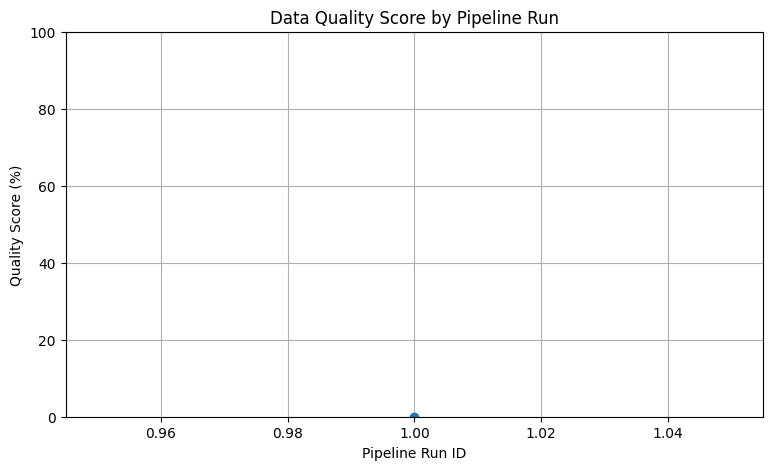

In [32]:
plt.figure(figsize=(9, 5))

plt.plot(
    pipeline_history["run_id"],
    pipeline_history["quality_score"],
    marker="o"
)

plt.title("Data Quality Score by Pipeline Run")
plt.xlabel("Pipeline Run ID")
plt.ylabel("Quality Score (%)")
plt.ylim(0, 100)
plt.grid(True)

plt.show()

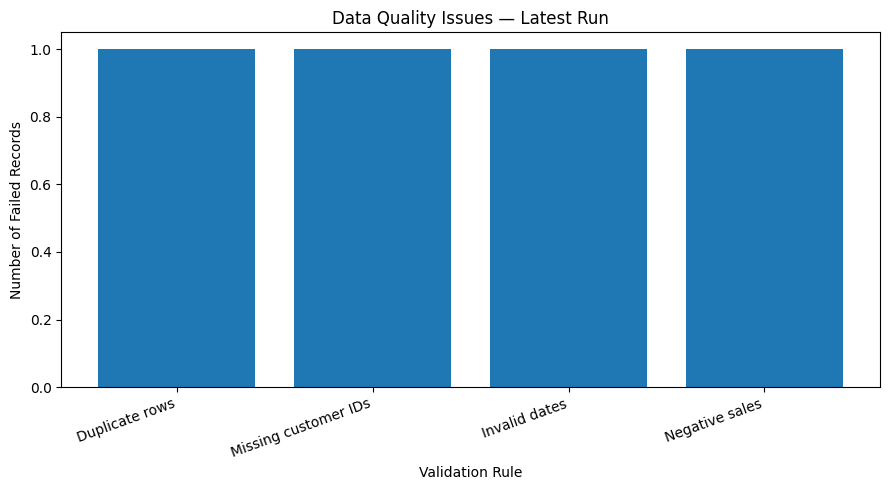

In [33]:
latest_run = pipeline_history.iloc[-1]

failure_counts = {
    "Duplicate rows": latest_run["duplicate_rows"],
    "Missing customer IDs": latest_run["missing_customer_ids"],
    "Invalid dates": latest_run["invalid_dates"],
    "Negative sales": latest_run["negative_sales"]
}

plt.figure(figsize=(9, 5))

plt.bar(
    failure_counts.keys(),
    failure_counts.values()
)

plt.title("Data Quality Issues — Latest Run")
plt.xlabel("Validation Rule")
plt.ylabel("Number of Failed Records")
plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.show()

In [34]:
import streamlit as st

print("Streamlit version:", st.__version__)
print("Streamlit is ready!")

Streamlit version: 1.44.1
Streamlit is ready!


In [37]:
import sqlite3
from pathlib import Path

db_path = Path(
    r"C:\Users\usha\OneDrive\Desktop\Data Quality & Pipeline Monitoring System\data_quality.db"
)

conn = sqlite3.connect(db_path)

columns = pd.read_sql_query(
    "PRAGMA table_info(validation_results);",
    conn
)

print(columns[["name", "type"]])

conn.close()

             name     type
0       result_id  INTEGER
1          run_id  INTEGER
2            rule     TEXT
3  failed_records  INTEGER
4          status     TEXT


In [38]:
import sqlite3

conn = sqlite3.connect(
    r"C:\Users\usha\OneDrive\Desktop\Data Quality & Pipeline Monitoring System\data_quality.db"
)

print(conn.execute(
    "PRAGMA table_info(validation_results)"
).fetchall())

conn.close()

[(0, 'result_id', 'INTEGER', 0, None, 1), (1, 'run_id', 'INTEGER', 0, None, 0), (2, 'rule', 'TEXT', 0, None, 0), (3, 'failed_records', 'INTEGER', 0, None, 0), (4, 'status', 'TEXT', 0, None, 0)]
